# 09 · Observability: Langfuse and LangSmith

A RAG system that works on the day you ship it will drift: documents change, users ask new things,
a provider changes a model, a prompt is edited. Modules 07 and 08 judge answers in batches. **Observability**
is the layer underneath that makes those judgements possible: a **trace** of every request that records
what was retrieved, what prompt the model saw, what it answered, how many tokens it used, how long each
step took, what it cost, and what scores were later attached to it.

This module builds a tiny tracer from scratch that runs offline (so you see every moving part), maps it
one-to-one onto the vocabulary of **Langfuse** (the open-source LLM tracing tool used in this portfolio),
shows the real Langfuse code as an optional cell that is **not executed here**, and then looks at
**LangSmith**, the other tool people ask about, and why we did not need it.

**You will learn**
1. What to record for an LLM application, and the vocabulary: trace, span, generation, score, session
2. A decorator-based tracer with token counting and cost from a price table
3. Attaching supervisor-style scores to traces
4. Reading a dashboard: cost per answer, latency percentiles, tokens, refusal rate
5. Finding the worst traces, the real payoff of tracing
6. The real Langfuse SDK (LiteLLM and LangChain hooks) and how LangSmith compares

## 1. What a trace is

Think of a trace as the black-box recorder of one request:

| Langfuse term | Meaning | In our RAG pipeline |
|---|---|---|
| **Trace** | one end-to-end request | the whole "answer this question" call |
| **Span** | a timed step inside the trace | `retrieve`, `build_prompt` |
| **Generation** | a span that is a model call: model name, input, output, token usage, cost | `generate` |
| **Score** | a number or label attached to a trace or span | `correct`, `faithfulness`, `refused` |
| **Session** | a group of traces from one conversation | four consecutive questions of one user |

Spans nest: the trace contains the retrieval span and the generation. With that structure you can answer
questions no log line can: *which step is slow, which questions cost the most, which answers were poorly
supported, what exactly did the model see when it got this one wrong?*

## 2. A tracer in forty lines

First the pipeline we want to observe: the Harbourview handbook, BM25 retrieval, and the same extractive
stand-in generator as module 01 (no model call is made anywhere in this notebook). Then the tracer.

Because the generator is a stand-in, **latency here is simulated** with a virtual clock (a model call is
charged a fixed overhead plus a time per output token, with seeded noise). The point is the bookkeeping, not
the speed of a real provider, and a virtual clock also makes every run of the notebook identical.
Token counts are estimated as 1.3 tokens per word, the usual rough rule for English; a real provider returns
exact counts in its response and you should record those instead.

In [1]:
# The Harbourview handbook: 22 passages, fictional, written for this course
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, question, gold passage, fact the answer must contain); None = the handbook does not say
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [2]:
import re, math, json, random, contextvars, itertools, statistics
import numpy as np
import matplotlib.pyplot as plt

# ---------- the pipeline to observe: BM25 retrieval + an extractive stand-in generator ----------
STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
tokens = lambda text: [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]
ids = [p[0] for p in PASSAGES]
chunks = [f"{section}. {text}" for _, section, text in PASSAGES]
tfs = [{} for _ in chunks]
for i, c in enumerate(chunks):
    for t in tokens(c):
        tfs[i][t] = tfs[i].get(t, 0) + 1
lens = np.array([sum(tf.values()) for tf in tfs], float)
df = {}
for tf in tfs:
    for t in tf:
        df[t] = df.get(t, 0) + 1
idf = {t: math.log(1 + (len(chunks) - c + 0.5) / (c + 0.5)) for t, c in df.items()}

def bm25_scores(query, k1=1.5, b=0.75):
    s = np.zeros(len(chunks))
    for t in set(tokens(query)):
        for i, tf in enumerate(tfs):
            f = tf.get(t, 0)
            if f and t in idf:
                s[i] += idf[t] * f * (k1 + 1) / (f + k1 * (1 - b + b * lens[i] / lens.mean()))
    return s

# ---------- a virtual clock, so latencies are reproducible ----------
class Clock:
    ms = 0.0
    @classmethod
    def advance(cls, ms):
        cls.ms += ms
rng = random.Random(7)

In [3]:
# ---------- the tracer ----------
PRICES = {"stand-in-small": (0.06, 0.24)}      # ASSUMED USD per million input / output tokens: check your provider's price list
OBS, TRACES = [], []                           # every observation, flat; every trace root
_current = contextvars.ContextVar("current", default=None)
_ids = itertools.count(1)

def observe(name=None, as_type="span"):
    # decorator: record a timed observation nested under whichever observation is running
    def deco(fn):
        def wrapper(*args, **kwargs):
            parent = _current.get()
            ob = dict(id=next(_ids), name=name or fn.__name__, type=as_type, parent=parent["id"] if parent else None,
                      start=Clock.ms, input=args[0] if args else None, usage=None, scores={}, session=None)
            if parent is None:
                TRACES.append(ob)
            OBS.append(ob)
            token = _current.set(ob)
            try:
                out = fn(*args, **kwargs)
                ob["output"] = out
                return out
            finally:
                ob["end"] = Clock.ms
                _current.reset(token)
        return wrapper
    return deco

def record_usage(model, text_in, text_out):
    # attach token usage and cost to the running generation
    ob = _current.get()
    n_in, n_out = round(len(text_in.split()) * 1.3), round(len(text_out.split()) * 1.3)
    price_in, price_out = PRICES[model]
    ob["usage"] = dict(model=model, input=n_in, output=n_out, cost=(n_in * price_in + n_out * price_out) / 1e6)
    return n_out

def score(trace, name, value):
    trace["scores"][name] = value

def children(trace):
    return [o for o in OBS if o["parent"] == trace["id"]]
print("tracer ready")

tracer ready


In [4]:
THRESHOLD = 1.0

@observe("retrieve")
def retrieve(question, k=2):
    Clock.advance(2 + rng.random() * 3)                       # a lexical search takes a few ms
    s = bm25_scores(question)
    return [(ids[i], float(s[i])) for i in np.argsort(-s)[:k]]

@observe("generate", as_type="generation")
def generate(question, hits):
    if hits[0][1] < THRESHOLD:
        text, prompt = "I cannot find that in the handbook.", question
    else:
        passages = [chunks[ids.index(pid)] for pid, _ in hits]
        prompt = "Answer only from these passages and cite them.\n" + "\n".join(passages) + "\nQuestion: " + question
        section, body = passages[0].split(". ", 1)
        q = set(tokens(question))
        text = max(re.split(r"(?<=[.!?])\s+", body), key=lambda s: len(q & set(tokens(s)))) + " [1]"
    n_out = record_usage("stand-in-small", prompt, text)
    Clock.advance(120 + 8 * n_out + rng.random() * 40)         # simulated model latency
    return text

@observe("answer_question")
def answer_question(question):
    hits = retrieve(question)
    return generate(question, hits)

t = answer_question("What wave height stops the crew boats from sailing?")
trace = TRACES[-1]
print("trace", trace["id"], trace["name"], f"{trace['end'] - trace['start']:.0f} ms")
for o in children(trace):
    extra = f"  model={o['usage']['model']} tokens in/out={o['usage']['input']}/{o['usage']['output']} cost=${o['usage']['cost']:.7f}" if o["usage"] else ""
    print(f"  span {o['name']:9s} [{o['type']}] {o['end'] - o['start']:6.0f} ms{extra}")

trace 1 answer_question 385 ms
  span retrieve  [span]      3 ms
  span generate  [generation]    382 ms  model=stand-in-small tokens in/out=122/32 cost=$0.0000150


That is the whole mechanism: a decorator opens an observation, nesting follows the call stack through a
context variable, and the generation carries a usage record. Langfuse stores exactly this shape (plus a web
interface), and its `@observe` decorator is used the same way, as you will see in section 6.

## 3. Real traffic, and scores attached to traces

One trace tells you nothing about the system; hundreds do. We simulate eighty requests in twenty sessions of
four: the 16 handbook questions plus 6 paraphrases, sampled at random. After each trace exists, a
**supervisor-style judge** (the idea of module 08, here a cheap rule version) attaches scores:

* `correct`: 1 if the answer contains the required fact, 0 otherwise (and 1 for a correct refusal)
* `faithfulness`: the share of the answer's content words that appear in the retrieved passages
* `refused`: 1 if the system said it could not find the answer

Scores are attached **after** the request, by a different process, at a different time. That is why traces
and scores are separate objects: the user already has an answer, and the quality verdict arrives later.

In [5]:
PARAPHRASES = [
    ("Are boats cancelled when the sea is too rough?", "1.5 m"), ("Can I go up the tower alone to fix something?", "forbidden"),
    ("How big are the blades?", "164 m"), ("Who do I call in the middle of the night about an accident?", "control room"),
    ("What if the oil in the gearbox gets dirty?", "filter change"), ("Do you stop work when whales or seals swim close?", "pause"),
]
POOL = [(q[1], q[3]) for q in QUESTIONS] + PARAPHRASES            # (question, required fact or None)

TRACES.clear(); OBS.clear(); Clock.ms = 0.0
rng = random.Random(7)
sample_rng = random.Random(11)
for s in range(20):
    for _ in range(4):
        question, fact = sample_rng.choice(POOL)
        answer_question(question)
        tr = TRACES[-1]
        tr["session"], tr["fact"] = f"session-{s:02d}", fact
        Clock.advance(sample_rng.randint(2000, 9000))           # the user reads and types the next question
print(len(TRACES), "traces,", len(OBS), "observations")

80 traces, 240 observations


In [6]:
def judge(tr):
    gen = next(o for o in children(tr) if o["type"] == "generation")
    retr = next(o for o in children(tr) if o["name"] == "retrieve")
    answer = tr["output"]
    refused = answer.startswith("I cannot find")
    context = " ".join(chunks[ids.index(pid)] for pid, _ in retr["output"]).lower()
    words = [w for w in tokens(answer.replace("[1]", ""))]
    faith = 1.0 if refused else sum(w in context for w in words) / max(len(words), 1)
    correct = int(refused) if tr["fact"] is None else int((tr["fact"] in answer) and not refused)
    score(tr, "refused", int(refused)); score(tr, "faithfulness", round(faith, 3)); score(tr, "correct", correct)

for tr in TRACES:
    judge(tr)
print({k: v for k, v in TRACES[0]["scores"].items()}, "<- scores of the first trace")

{'refused': 1, 'faithfulness': 1.0, 'correct': 1} <- scores of the first trace


## 4. The dashboard

Everything below is computed from the trace list, nothing else: this is what a Langfuse dashboard shows,
and it is the first thing to look at when someone says "the assistant feels worse this week".

traces               80
latency p50 / p95    311 / 395 ms
tokens in / out      88 / 19 per answer (mean)
cost per answer      $0.0000099 mean, $0.00079 in total
refusal rate         11.2%
correct              65.0%   mean faithfulness 1.00
input tokens are 54% of the cost; correlation of cost with input tokens 0.87, with output tokens 0.89


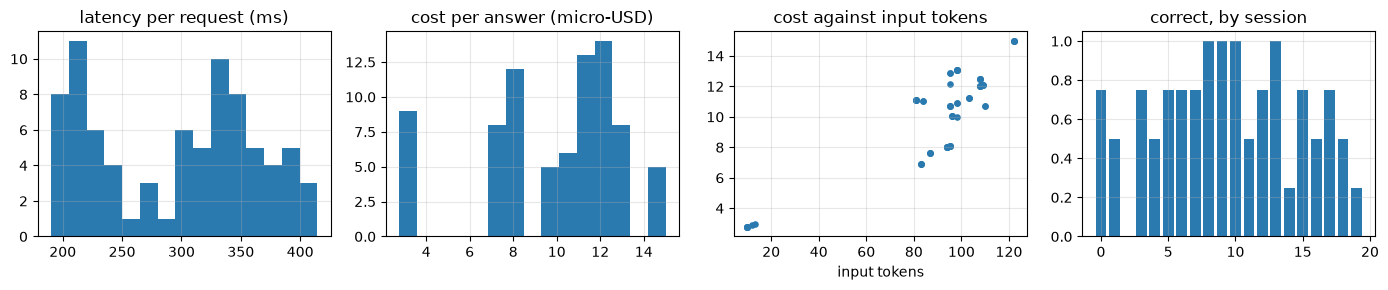

In [7]:
def duration(tr): return tr["end"] - tr["start"]
def gen_of(tr): return next(o for o in children(tr) if o["type"] == "generation")
lat = np.array([duration(t) for t in TRACES])
cost = np.array([gen_of(t)["usage"]["cost"] for t in TRACES])
tok_in = np.array([gen_of(t)["usage"]["input"] for t in TRACES]); tok_out = np.array([gen_of(t)["usage"]["output"] for t in TRACES])
refused = np.array([t["scores"]["refused"] for t in TRACES]); correct = np.array([t["scores"]["correct"] for t in TRACES])
faith = np.array([t["scores"]["faithfulness"] for t in TRACES])

print(f"traces               {len(TRACES)}")
print(f"latency p50 / p95    {np.percentile(lat, 50):.0f} / {np.percentile(lat, 95):.0f} ms")
print(f"tokens in / out      {tok_in.mean():.0f} / {tok_out.mean():.0f} per answer (mean)")
print(f"cost per answer      ${cost.mean():.7f} mean, ${cost.sum():.5f} in total")
print(f"refusal rate         {refused.mean():.1%}")
print(f"correct              {correct.mean():.1%}   mean faithfulness {faith.mean():.2f}")
in_cost = tok_in * PRICES["stand-in-small"][0] / 1e6
print(f"input tokens are {in_cost.sum() / cost.sum():.0%} of the cost; correlation of cost with input tokens {np.corrcoef(cost, tok_in)[0, 1]:.2f}, with output tokens {np.corrcoef(cost, tok_out)[0, 1]:.2f}")

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
ax[0].hist(lat, bins=15, color="#2a7ab0"); ax[0].set_title("latency per request (ms)")
ax[1].hist(cost * 1e6, bins=15, color="#2a7ab0"); ax[1].set_title("cost per answer (micro-USD)")
ax[2].scatter(tok_in, cost * 1e6, s=14, color="#2a7ab0"); ax[2].set_xlabel("input tokens"); ax[2].set_title("cost against input tokens")
by_session = [np.mean([t["scores"]["correct"] for t in TRACES if t["session"] == f"session-{s:02d}"]) for s in range(20)]
ax[3].bar(range(20), by_session, color="#2a7ab0"); ax[3].set_title("correct, by session"); ax[3].set_ylim(0, 1.05)
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

Three habits to take from the dashboard:

1. **Report percentiles, not means.** The p95 is the experience one user in twenty has.
2. **Know what drives cost.** Every answer pays for the passages it was given plus the answer it writes. In
   this run the printed split shows how much comes from input and how much from output, and which of the two
   tracks the cost more closely. Output tokens cost more each, so with a real, chattier model the picture
   changes: record the split from your own traces before deciding whether to retrieve fewer passages or to
   ask for shorter answers.
3. **A rate has to be read next to its quality.** A falling refusal rate is good news only if `correct` and
   `faithfulness` hold; otherwise the system has simply started guessing. (Here faithfulness is 1.00 for
   every answer **by construction**: an extractive generator can only copy sentences it was given, so this
   score cannot discriminate. With a real model it is the score that catches invented claims. A metric that
   never moves is a metric to question.)

## 5. Finding the worst traces

Aggregates tell you something is wrong; **individual traces tell you what**. Sort by a score and open the
bad ones: you get the question, the passages that were retrieved, and the answer, all on one screen.

In [8]:
bad = [t for t in TRACES if t["scores"]["correct"] == 0]
seen = {}
for t in bad:
    seen.setdefault(t["input"], t)
print(f"{len(bad)} incorrect traces, {len(seen)} distinct questions:\n")
for question, t in seen.items():
    retr = next(o for o in children(t) if o["name"] == "retrieve")
    print(f"Q: {question}\n   retrieved {[(p, round(s, 1)) for p, s in retr['output']]} (needed {t['fact']!r})\n   A: {t['output']}\n")

28 incorrect traces, 9 distinct questions:

Q: Are boats cancelled when the sea is too rough?
   retrieved [('p15', 2.6), ('p22', 2.4)] (needed '1.5 m')
   A: Nothing is discharged at sea. [1]

Q: What if the oil in the gearbox gets dirty?
   retrieved [('p07', 6.9), ('p06', 2.7)] (needed 'filter change')
   A: Gearbox oil is sampled every six months. [1]

Q: What do I do if the pitch fault comes back after a reset?
   retrieved [('p10', 8.0), ('p16', 2.2)] (needed 'replace the hydraulic accumulator')
   A: A pitch system fault (code PF-203) usually means a low accumulator pressure. [1]

Q: Can I go up the tower alone to fix something?
   retrieved [('p01', 0.0), ('p02', 0.0)] (needed 'forbidden')
   A: I cannot find that in the handbook.

Q: Who do I call in the middle of the night about an accident?
   retrieved [('p14', 3.0), ('p06', 2.7)] (needed 'control room')
   A: Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced

Each failure is one of the two kinds from module 01: either the retrieved ids do not include the passage
that holds the fact (a retrieval miss, fixed by module 02's techniques or by editing the documents), or they
do and the generator chose badly (fixed in the prompt or the model). Without the trace you would only know
"it answered wrong".

## 6. The real thing: Langfuse

Langfuse is open source, can be self-hosted or used as a cloud service, and its Python SDK (version 5, built
on OpenTelemetry) gives you the same objects as our tracer. The cell below is the production version of
sections 2 and 3. **It is not executed in this notebook**: it needs a Langfuse project and keys
(`LANGFUSE_PUBLIC_KEY`, `LANGFUSE_SECRET_KEY`, `LANGFUSE_HOST`), and the executed results of this course never
depend on a key. With the variables unset the cell only prints a message.

In [9]:
import os

if os.getenv("LANGFUSE_PUBLIC_KEY") and os.getenv("LANGFUSE_SECRET_KEY"):
    from langfuse import observe, get_client

    langfuse = get_client()                                   # reads LANGFUSE_* from the environment

    @observe(as_type="generation")                            # a model call: usage and cost are attached to it
    def generate_real(question, passages):
        langfuse.update_current_generation(model="your-model-id", usage_details={"input": 812, "output": 61})
        return "..."

    @observe()                                                # the trace root: nested @observe calls become spans
    def answer_real(question):
        langfuse.update_current_trace(session_id="session-01", user_id="user-17")
        hits = ["..."]
        return generate_real(question, hits)

    answer_real("What wave height stops the crew boats from sailing?")
    # the supervisor of module 08 attaches its verdict later, from another process, by trace id:
    langfuse.create_score(trace_id="<trace id>", name="faithfulness", value=0.92, data_type="NUMERIC", comment="judge: all claims cited")
    langfuse.flush()                                          # send pending events before the process exits
else:
    print("LANGFUSE_* not set: the real-SDK cell was skipped (this is the expected state for the course).")

LANGFUSE_* not set: the real-SDK cell was skipped (this is the expected state for the course).


Two integrations matter more than the decorator, because they trace code you did not write:

* **LiteLLM** (module 04): `litellm.success_callback = ["langfuse"]` and `litellm.failure_callback = ["langfuse"]`
  record every model call routed through it, with model, tokens and cost, whichever provider is behind it.
* **LangChain and LangGraph** (modules 03 and 05): pass `from langfuse.langchain import CallbackHandler` as a
  callback in the call's `config={"callbacks": [handler]}` and every chain step, retriever call and model call
  becomes a nested observation.

In the wind-farm analytics agent of this portfolio, Langfuse was attached exactly that way: through the
LiteLLM router and the LangChain callbacks, with tracing switched off when no keys are configured, so the
application runs identically with or without it.

## 7. LangSmith, and why we did not use it

**LangSmith** is the tracing, evaluation and dataset product from the makers of LangChain. It does the same
core job as Langfuse (traces, runs, feedback scores) and adds first-class prompt hubs and dataset-driven
evaluation runs that are tightly integrated with LangChain and LangGraph.

| | Langfuse | LangSmith |
|---|---|---|
| Licence and hosting | open source, self-hostable or cloud | hosted product (self-hosting is an enterprise option) |
| Framework fit | any code, plus LiteLLM, LangChain, OpenAI-style SDKs, OpenTelemetry | designed around LangChain and LangGraph, works with others |
| Traces, scores, sessions | yes | yes (runs, feedback, threads) |
| Datasets and experiments | yes | yes, a core strength |
| Prompt management | yes | yes (prompt hub) |
| Used in this portfolio | **yes** | **no** |

**The honest reason we did not use LangSmith:** Langfuse already covered tracing, and a second stack would
have meant another external account, another set of keys and another place for prompts and answers to live,
with no functional gain. Nothing is wrong with LangSmith; for a team that is all-in on LangChain and wants
its hosted evaluation workflow it is a reasonable first choice. Choose by where your data may live, how your
code calls models, and what you already run, and note that because both speak in traces, spans and scores,
moving between them is a small change in the instrumentation layer, not a rewrite.

No LangSmith code is executed in this course, for the same reason.

## Exercises

1. Add a `retrieved_ids` field to the generation and a score `hit` (is the gold passage in it?). Then plot
   `hit` against `correct` over the traces. What does the cross-tab say about where failures come from?
2. Change `PRICES` to ten times the output price. How does cost per answer move and which side dominates
   now? Then change `k` in `retrieve` from 2 to 4: how much does cost move, and how does `correct` change?
3. Make the stand-in generator occasionally raise an exception. Where would your tracer need a `status` field
   so that failed calls show up on the dashboard instead of disappearing?
4. Log a `session` score: the share of a session's traces that were refusals. Which sessions would you open
   first, and what would you look for?